Problema: "O problema abordado é a insatisfação silenciosa. Uma nota baixa (1 estrela) é prejudicial para a reputação da plataforma, mas muitas vezes a empresa só descobre o problema depois que a avaliação negativa já foi publicada."

In [ ]:
import pandas as pd
import kagglehub

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Brazilian E-Commerce Public Dataset by Olist

In [ ]:
# 1. Carregamento dos Dados
path = kagglehub.dataset_download("olistbr/brazilian-ecommerce")

orders = pd.read_csv(path + '/olist_orders_dataset.csv')
reviews = pd.read_csv(path + '/olist_order_reviews_dataset.csv')
items = pd.read_csv(path + '/olist_order_items_dataset.csv')
products = pd.read_csv(path + '/olist_products_dataset.csv')

Using Colab cache for faster access to the 'brazilian-ecommerce' dataset.


# Tratamento dos dados

In [ ]:
# 2. Pré-processamento de Datas (Essencial para calcular atrasos)
cols_data = ['order_purchase_timestamp', 'order_estimated_delivery_date', 'order_delivered_customer_date']
for col in cols_data:
    orders[col] = pd.to_datetime(orders[col])

# 3. Filtragem: Vamos trabalhar apenas com pedidos entregues para ter certeza do prazo
orders = orders[orders['order_status'] == 'delivered'].copy()

In [ ]:
# 4. Criação da Variável de Atraso (Feature Engineering)
# Se a data de entrega for maior que a estimada, é atraso.
orders['days_late'] = (orders['order_delivered_customer_date'] - orders['order_estimated_delivery_date']).dt.days
# Se o número for negativo, chegou adiantado. Se positivo, atrasou.
# Para simplificar, vamos criar uma flag binária também: 1 = Atrasou, 0 = No Prazo
orders['is_late'] = orders['days_late'].apply(lambda x: 1 if x > 0 else 0)

In [ ]:
# 5. Tratamento de Reviews (O Alvo)
# Um pedido pode ter mais de um review se mudar. Vamos pegar o mais recente ou remover duplicatas.
reviews = reviews.drop_duplicates(subset=['order_id'], keep='first')

# Criação da variável ALVO (Target): 0 = Satisfeito (4-5), 1 = Insatisfeito (1-3)
reviews['is_bad_review'] = reviews['review_score'].apply(lambda x: 1 if x <= 3 else 0)

In [ ]:
# 6. Fusão das Tabelas (O "Join" Gigante)

# Passo A: Orders + Reviews
# Usamos LEFT join porque queremos todos os pedidos, mesmo sem review (no futuro, para prever)
# Mas para TREINO, precisamos de reviews, então aqui usaremos INNER ou filtraremos depois.
df = pd.merge(orders, reviews[['order_id', 'review_score', 'is_bad_review']], on='order_id', how='inner')

In [ ]:
# Passo B: + Items
# Atenção: Um pedido pode ter vários itens. Isso duplicaria as linhas do pedido.
# Para este projeto simples, vamos pegar apenas o PRIMEIRO item de cada pedido para não enviesar o modelo.
items_unique = items.drop_duplicates(subset=['order_id'], keep='first')
df = pd.merge(df, items_unique[['order_id', 'product_id', 'price', 'freight_value']], on='order_id', how='inner')

# Passo C: + Products
df = pd.merge(df, products[['product_id', 'product_photos_qty', 'product_description_lenght']], on='product_id', how='left')

# 7. Limpeza Final
# Selecionando apenas as colunas que importam para o modelo
colunas_finais = [
    'days_late',                # Atraso em dias (numérico)
    'is_late',                  # Atrasou? (binário)
    'price',                    # Preço do item
    'freight_value',            # Valor do frete
    'product_description_lenght', # Tamanho da descrição
    'product_photos_qty',       # Qtd de fotos
    'is_bad_review'             # ALVO (O que queremos prever)
]

df_final = df[colunas_finais].dropna() # Remove linhas com dados faltando

print(f"Tamanho final do Dataset: {df_final.shape}")
print("Amostra dos dados prontos para o modelo:")
print(df_final.head())

Tamanho final do Dataset: (94474, 7)
Amostra dos dados prontos para o modelo:
   days_late  is_late   price  freight_value  product_description_lenght  \
0       -8.0        0   29.99           8.72                       268.0   
1       -6.0        0  118.70          22.76                       178.0   
2      -18.0        0  159.90          19.22                       232.0   
3      -13.0        0   45.00          27.20                       468.0   
4      -10.0        0   19.90           8.72                       316.0   

   product_photos_qty  is_bad_review  
0                 4.0              0  
1                 1.0              0  
2                 1.0              0  
3                 3.0              0  
4                 4.0              0  


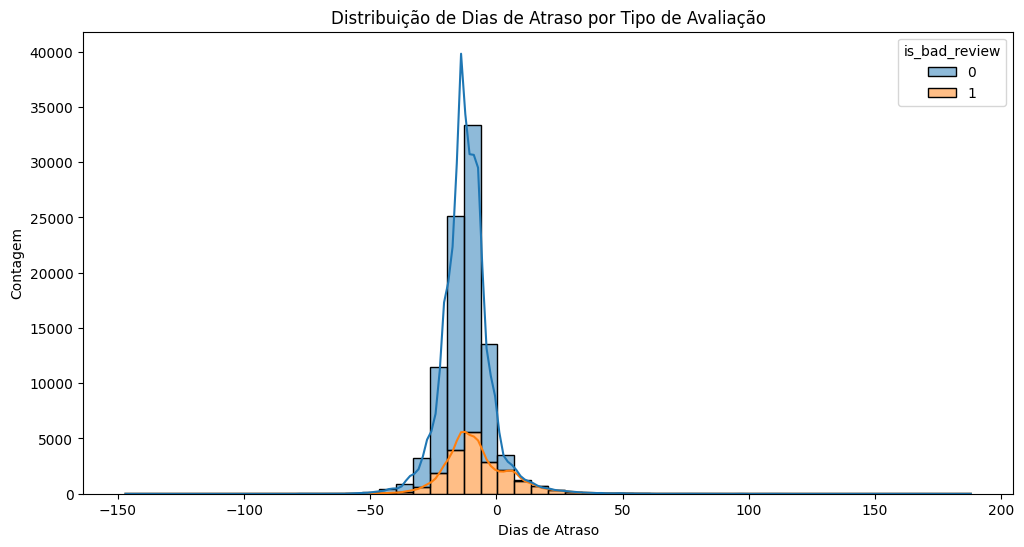

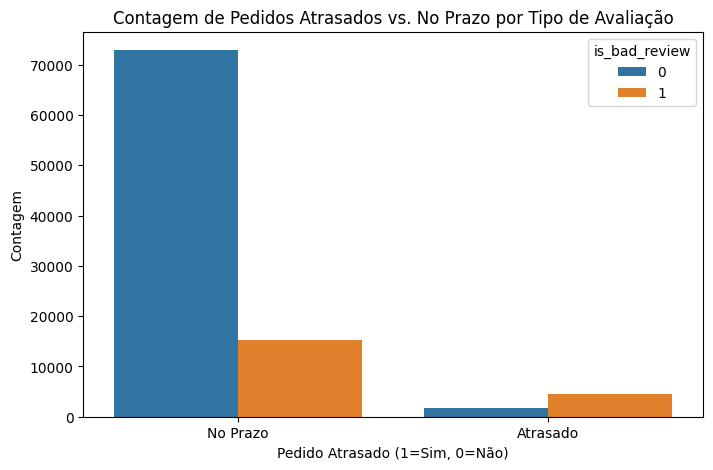

In [ ]:
# Visualização sugerida 1: Distribuição de 'days_late' para reviews ruins vs. bons
# df_final é o DataFrame tratado, disponível no estado atual do notebook
plt.figure(figsize=(12, 6))
sns.histplot(data=df_final, x='days_late', hue='is_bad_review', kde=True, multiple="stack", bins=50)
plt.title('Distribuição de Dias de Atraso por Tipo de Avaliação')
plt.xlabel('Dias de Atraso')
plt.ylabel('Contagem')
plt.show()

# Visualização sugerida 2: Proporção de pedidos atrasados por tipo de avaliação
plt.figure(figsize=(8, 5))
sns.countplot(data=df_final, x='is_late', hue='is_bad_review')
plt.title('Contagem de Pedidos Atrasados vs. No Prazo por Tipo de Avaliação')
plt.xlabel('Pedido Atrasado (1=Sim, 0=Não)')
plt.ylabel('Contagem')
plt.xticks([0, 1], ['No Prazo', 'Atrasado'])
plt.show()

# Treinando o modelo

In [ ]:
# 1. Separar o que é "Dica" (X) do que é "Resposta" (y)
X = df_final.drop('is_bad_review', axis=1)  # Todas as colunas, menos a resposta
y = df_final['is_bad_review']               # Apenas a resposta (0 ou 1)

In [ ]:
# 2. Dividir em Treino (70%) e Teste (30%)
# Isso serve para ver se o modelo aprendeu de verdade ou só decorou (overfitting)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [ ]:
# 3. Criar e Treinar o Modelo (Random Forest)
model = RandomForestClassifier(n_estimators=100, random_state=42)
print("Treinando o modelo... (pode demorar alguns segundos)")
model.fit(X_train, y_train)

Treinando o modelo... (pode demorar alguns segundos)


RandomForestClassifier(random_state=42)

In [ ]:
# 4. Fazer Previsões (Teste Cego)
# O modelo vai tentar adivinhar o resultado dos 30% que ele nunca viu
y_pred = model.predict(X_test)

In [ ]:
# 5. Avaliar os Resultados
print("\n--- RESULTADOS DO MODELO ---")
print(f"Acurácia Geral: {accuracy_score(y_test, y_pred):.2%}")
print("\nRelatório Detalhado:")
print(classification_report(y_test, y_pred))


--- RESULTADOS DO MODELO ---
Acurácia Geral: 80.94%

Relatório Detalhado:
              precision    recall  f1-score   support

           0       0.83      0.96      0.89     22398
           1       0.62      0.24      0.35      5945

    accuracy                           0.81     28343
   macro avg       0.72      0.60      0.62     28343
weighted avg       0.78      0.81      0.78     28343



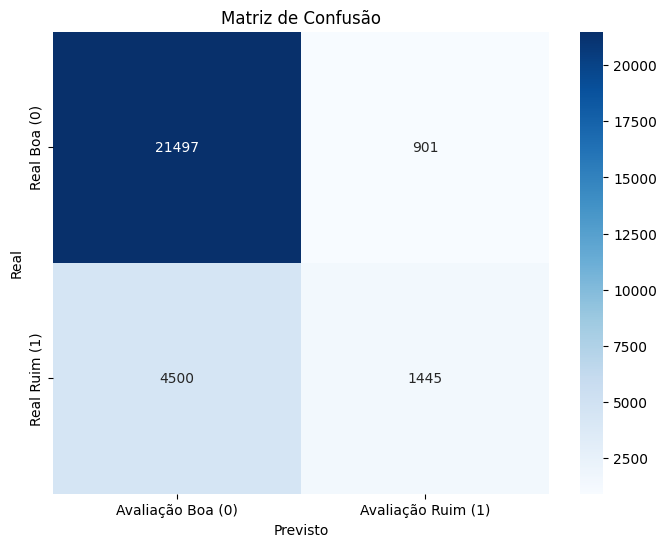

In [ ]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Avaliação Boa (0)', 'Avaliação Ruim (1)'],
            yticklabels=['Real Boa (0)', 'Real Ruim (1)'])
plt.xlabel('Previsto')
plt.ylabel('Real')
plt.title('Matriz de Confusão')
plt.show()

In [ ]:
# 6. O Pulo do Gato: Quais variáveis importaram mais?
# Isso gera o dado para o seu slide ("O atraso impacta X%")
feature_importances = pd.DataFrame(model.feature_importances_,
                                   index = X.columns,
                                   columns=['importance']).sort_values('importance', ascending=False)
print("\n--- O QUE MAIS CAUSA INSATISFAÇÃO? ---")
print(feature_importances)


--- O QUE MAIS CAUSA INSATISFAÇÃO? ---
                            importance
freight_value                 0.233904
days_late                     0.232595
product_description_lenght    0.230940
price                         0.215063
product_photos_qty            0.046012
is_late                       0.041487


/tmp/ipython-input-2648086468.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=feature_importances['importance'], y=feature_importances.index, palette='viridis')


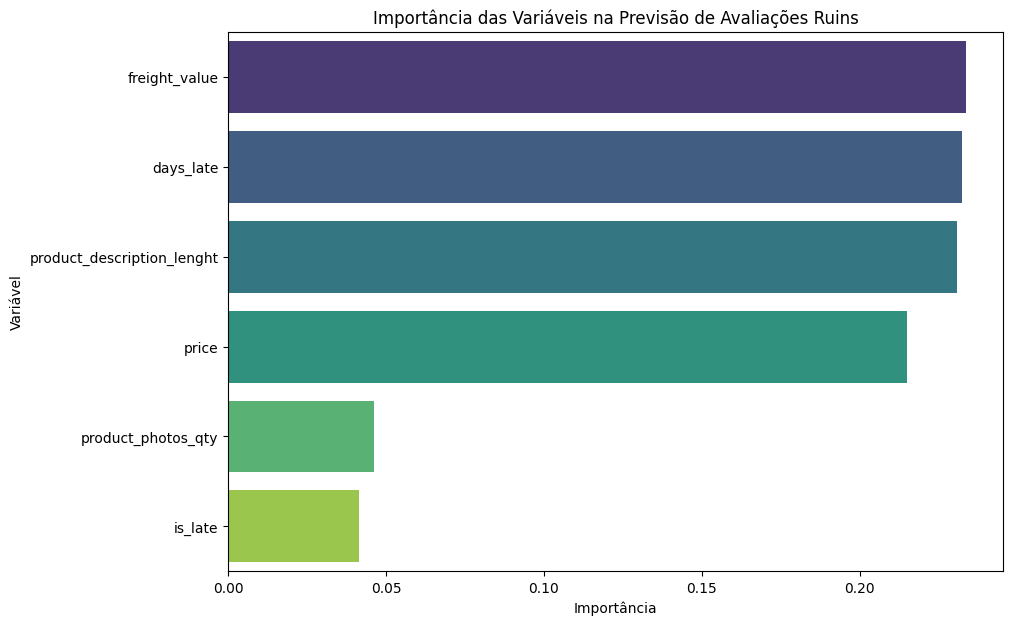

In [ ]:
# A importância das features
plt.figure(figsize=(10, 7))
sns.barplot(x=feature_importances['importance'], y=feature_importances.index, palette='viridis')
plt.title('Importância das Variáveis na Previsão de Avaliações Ruins')
plt.xlabel('Importância')
plt.ylabel('Variável')
plt.show()

Na prática, esse modelo serve como um Sistema de Alerta Antecipado. Se o sistema prevê uma avaliação ruim, o suporte da Olist pode entrar em contato com o cliente para pedir desculpas ou oferecer um desconto antes mesmo dele pensar em reclamar publicamente."

O uso de Machine Learning aqui transforma o suporte ao cliente de reativo para proativo, protegendo a marca e retendo clientes. Obrigado.